# 03 · Model training and evaluation

Training is run from the command line because the hyper-parameter search takes about 15 minutes:

```bash
python -m src.train      # tune on validation, walk-forward CV, refit, save models
python -m src.evaluate   # test-period metrics, figures, importance, unseen-car-park test
```

This notebook loads those saved outputs and **re-computes the headline test score from the saved model** to prove the reported numbers are real.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from IPython.display import Image, display
from src import config as C

In [2]:
tr = json.loads((C.METRICS_DIR / 'training_summary.json').read_text())
ev = json.loads((C.METRICS_DIR / 'evaluation_summary.json').read_text())
for h in ('30', '60'):
    print(h, 'min | rows', tr[h]['rows'], '| folds', tr[h]['walk_forward_folds'])

30 min | rows {'train': 21157, 'val': 5374, 'test': 6072} | folds [['2016-11-06', '2016-11-12'], ['2016-11-13', '2016-11-19'], ['2016-11-20', '2016-11-26'], ['2016-11-27', '2016-12-05']]
60 min | rows {'train': 19912, 'val': 5080, 'test': 5739} | folds [['2016-11-06', '2016-11-12'], ['2016-11-13', '2016-11-19'], ['2016-11-20', '2016-11-26'], ['2016-11-27', '2016-12-05']]


## Hyper-parameter tuning (validation fortnight)

In [3]:
rows = []
for h in ('30', '60'):
    for m, d in tr[h]['regression'].items():
        rows.append({'horizon': h, 'model': m, 'best_params': d['best_params'], 'val_MAE_pp': d['validation_MAE']*100, 'grid_size': len(d['tuning_log'])})
pd.DataFrame(rows)

,horizon,model,best_params,val_MAE_pp,grid_size
0,30,Persistence (baseline),{},3.831,1
1,30,Historical profile (baseline),{},7.449,1
2,30,Persistence + weekly shape (baseline),{},1.582,1
3,30,Ridge Regression,{'model__alpha': 0.1},1.653,4
4,30,Random Forest,"{'model__max_depth': 20, 'model__max_features'...",1.425,18
5,30,HistGradientBoosting,"{'model__l2_regularization': 1.0, 'model__lear...",1.303,24
6,60,Persistence (baseline),{},7.355,1
7,60,Historical profile (baseline),{},7.597,1
8,60,Persistence + weekly shape (baseline),{},2.468,1
9,60,Ridge Regression,{'model__alpha': 0.1},2.683,4


## Walk-forward validation (4 expanding weekly folds) – used to select the model

In [4]:
pd.DataFrame([{'horizon': h, 'model': m, **{r['fold']: round(r['MAE']*100, 3) for r in d['walk_forward']}, 'mean': d['walk_forward_MAE_mean']*100} for h in ('30','60') for m, d in tr[h]['regression'].items()])

,horizon,model,2016-11-06..2016-11-12,2016-11-13..2016-11-19,2016-11-20..2016-11-26,2016-11-27..2016-12-05,mean
0,30,Persistence (baseline),3.402,3.428,3.708,3.896,3.609
1,30,Historical profile (baseline),4.937,5.786,7.899,6.910,6.383
2,30,Persistence + weekly shape (baseline),1.435,1.374,1.496,1.674,1.495
3,30,Ridge Regression,1.622,1.470,1.616,1.737,1.611
4,30,Random Forest,1.350,1.336,1.492,1.393,1.393
5,30,HistGradientBoosting,1.248,1.257,1.403,1.254,1.290
6,60,Persistence (baseline),6.451,6.532,7.144,7.466,6.899
7,60,Historical profile (baseline),5.052,5.862,8.024,7.074,6.503
8,60,Persistence + weekly shape (baseline),2.108,1.945,2.434,2.545,2.258
9,60,Ridge Regression,2.676,2.377,2.752,2.744,2.637


## Test fortnight (never used for any decision)

In [5]:
for h in ('60', '30'):
    print(f'--- {h} minutes ahead ---')
    display(pd.DataFrame(ev[h]['regression_table']).drop(columns=['Selected']).round(3))

--- 60 minutes ahead ---


,Model,Test MAE (pp),Test RMSE (pp),Test R2,Test MAE (spaces),MAE vs persistence (%),Walk-forward MAE (pp),Walk-forward MAE std (pp),Validation MAE (pp),Fit time (s),Predict ms / 1000 rows
0,Persistence (baseline),7.073,10.065,0.852,97.263,0.000,6.899,0.423,7.355,0.00,0.006
1,Historical profile (baseline),7.237,9.991,0.854,101.709,-2.326,6.503,1.135,7.597,0.01,0.253
2,Persistence + weekly shape (baseline),2.787,4.852,0.966,34.415,60.589,2.258,0.242,2.468,0.00,0.022
3,Ridge Regression,2.826,4.156,0.975,35.331,60.037,2.637,0.153,2.683,0.05,1.383
4,Random Forest,2.288,3.446,0.983,27.888,67.656,2.236,0.115,2.269,20.71,45.454
5,HistGradientBoosting,2.021,2.999,0.987,24.655,71.426,2.055,0.189,2.113,4.10,20.644


--- 30 minutes ahead ---


,Model,Test MAE (pp),Test RMSE (pp),Test R2,Test MAE (spaces),MAE vs persistence (%),Walk-forward MAE (pp),Walk-forward MAE std (pp),Validation MAE (pp),Fit time (s),Predict ms / 1000 rows
0,Persistence (baseline),3.671,5.248,0.961,49.914,0.000,3.609,0.205,3.831,0.00,0.009
1,Historical profile (baseline),7.104,9.882,0.862,99.552,-93.534,6.383,1.120,7.449,0.01,0.227
2,Persistence + weekly shape (baseline),1.708,2.790,0.989,20.707,53.477,1.495,0.112,1.582,0.00,0.024
3,Ridge Regression,1.621,2.359,0.992,19.994,55.847,1.611,0.095,1.653,0.07,1.407
4,Random Forest,1.373,2.004,0.994,16.660,62.610,1.393,0.061,1.425,13.05,48.244
5,HistGradientBoosting,1.264,1.831,0.995,15.319,65.553,1.290,0.065,1.303,4.00,23.157


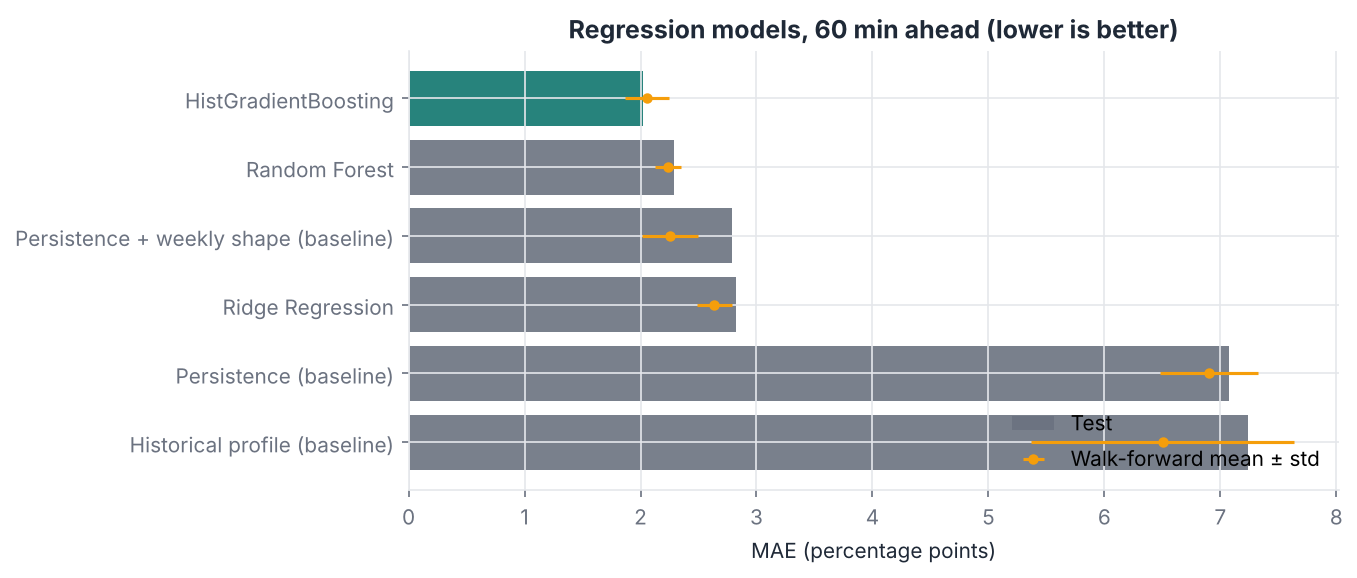

In [6]:
display(Image(ROOT / 'outputs/figures/eval_model_comparison_h60.png'))

### Verify: recompute the selected model's test MAE from the saved file

In [7]:
from src.data_preprocessing import load_grid
from src.feature_engineering import build_features, split_by_date, FEATURES
from src.predict import load_bundle
from sklearn.metrics import mean_absolute_error
grid = load_grid()
for h in (30, 60):
    b = load_bundle(h)
    test = split_by_date(build_features(grid, h, codes=b['park_codes']))['test']
    mae = mean_absolute_error(test['target_rate'], np.clip(b['regressor'].predict(test[FEATURES]), 0, 1)) * 100
    rep = [r for r in ev[str(h)]['regression_table'] if r['Selected']][0]['Test MAE (pp)']
    print(f'{h} min: recomputed {mae:.4f} pp | reported {rep:.4f} pp | model {b["regressor_name"]}')

30 min: recomputed 1.2645 pp | reported 1.2645 pp | model HistGradientBoosting


60 min: recomputed 2.0209 pp | reported 2.0209 pp | model HistGradientBoosting


## Status classification

In [8]:
for h in ('60', '30'):
    print(f'--- {h} minutes ahead ---')
    display(pd.DataFrame(ev[h]['classification_table'])[['Model','accuracy','macro_precision','macro_recall','macro_F1','weighted_F1','FULL_precision','FULL_recall','HIGH_recall','Walk-forward macro F1']].round(3))

--- 60 minutes ahead ---


,Model,accuracy,macro_precision,macro_recall,macro_F1,weighted_F1,FULL_precision,FULL_recall,HIGH_recall,Walk-forward macro F1
0,Majority class (baseline),0.408,0.102,0.250,0.145,0.236,0.000,0.000,0.000,0.160
1,Persistence (baseline),0.770,0.738,0.719,0.725,0.761,0.778,0.741,0.526,0.717
2,Logistic Regression,0.904,0.881,0.889,0.885,0.904,0.879,0.898,0.825,0.873
3,Random Forest,0.917,0.900,0.899,0.899,0.918,0.917,0.872,0.855,0.897
4,HistGradientBoosting,0.916,0.898,0.895,0.896,0.916,0.906,0.884,0.822,0.890
5,Thresholded HistGradientBoosting,0.932,0.919,0.912,0.915,0.931,0.932,0.880,0.863,0.901


--- 30 minutes ahead ---


,Model,accuracy,macro_precision,macro_recall,macro_F1,weighted_F1,FULL_precision,FULL_recall,HIGH_recall,Walk-forward macro F1
0,Majority class (baseline),0.435,0.109,0.250,0.152,0.263,0.000,0.000,0.000,0.166
1,Persistence (baseline),0.878,0.858,0.846,0.851,0.875,0.882,0.866,0.734,0.844
2,Logistic Regression,0.944,0.925,0.934,0.930,0.945,0.912,0.944,0.886,0.920
3,Random Forest,0.949,0.934,0.937,0.935,0.950,0.935,0.929,0.899,0.934
4,HistGradientBoosting,0.949,0.933,0.935,0.934,0.949,0.932,0.929,0.892,0.932
5,Thresholded HistGradientBoosting,0.954,0.942,0.938,0.940,0.954,0.946,0.914,0.903,0.940


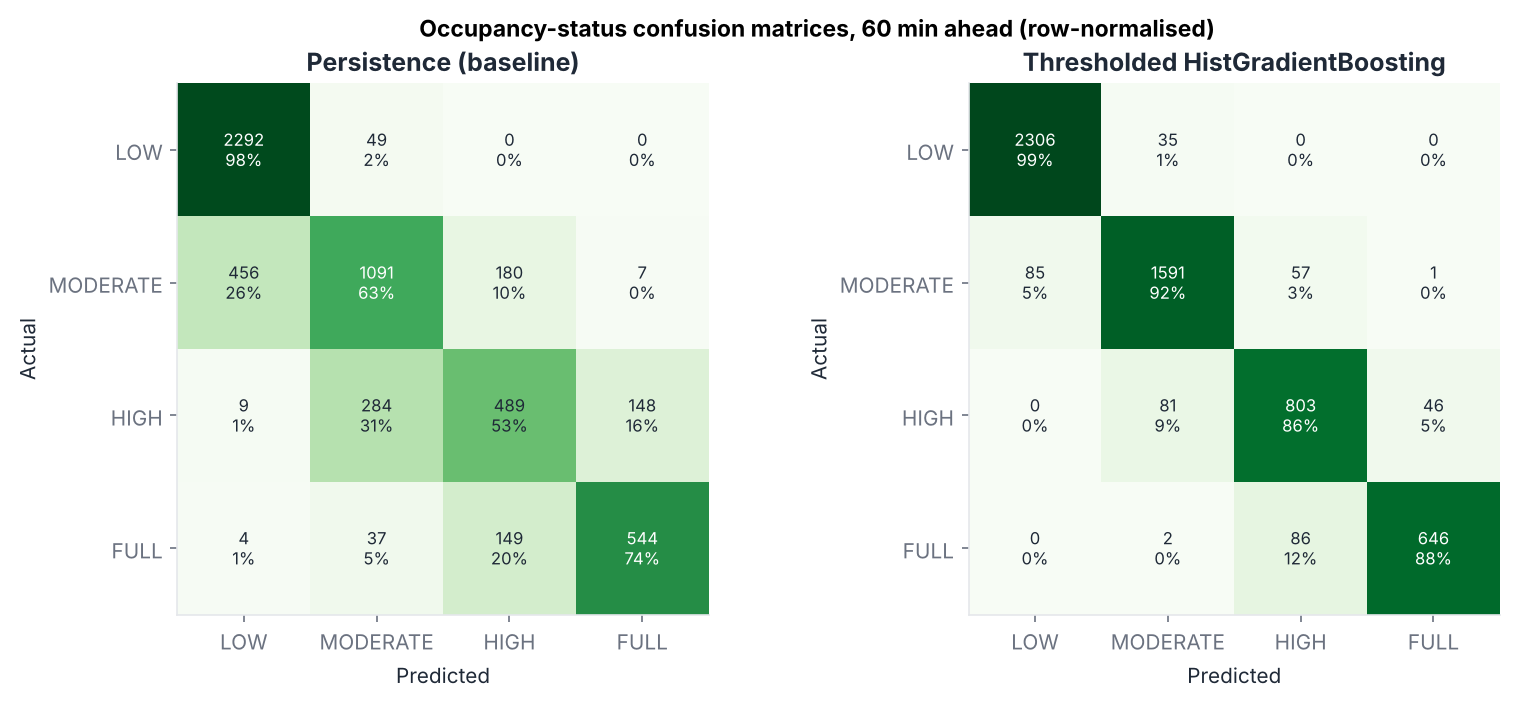

{'full_actual': 734,
 'full_missed': 88,
 'full_missed_as_low_or_moderate': 2,
 'false_full_alarms': 47}

In [9]:
display(Image(ROOT / 'outputs/figures/eval_confusion_h60.png'))
{k: ev['60'][k] for k in ('full_actual','full_missed','full_missed_as_low_or_moderate','false_full_alarms')}

## Error analysis

In [10]:
pd.DataFrame(ev['60']['segments']).T.round(3)

,n,selected_MAE_pp,persistence_MAE_pp,weekly_shape_MAE_pp
peak (12:00-15:00),2508.0,1.803,4.060,2.485
off-peak,3231.0,2.190,9.411,3.022
weekday,4181.0,1.844,7.258,2.177
weekend,1558.0,2.496,6.575,4.425


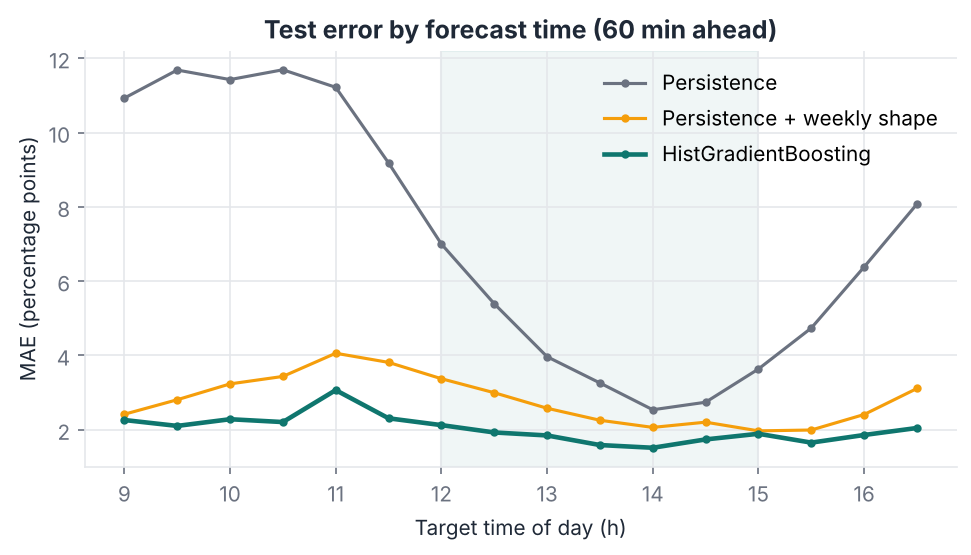

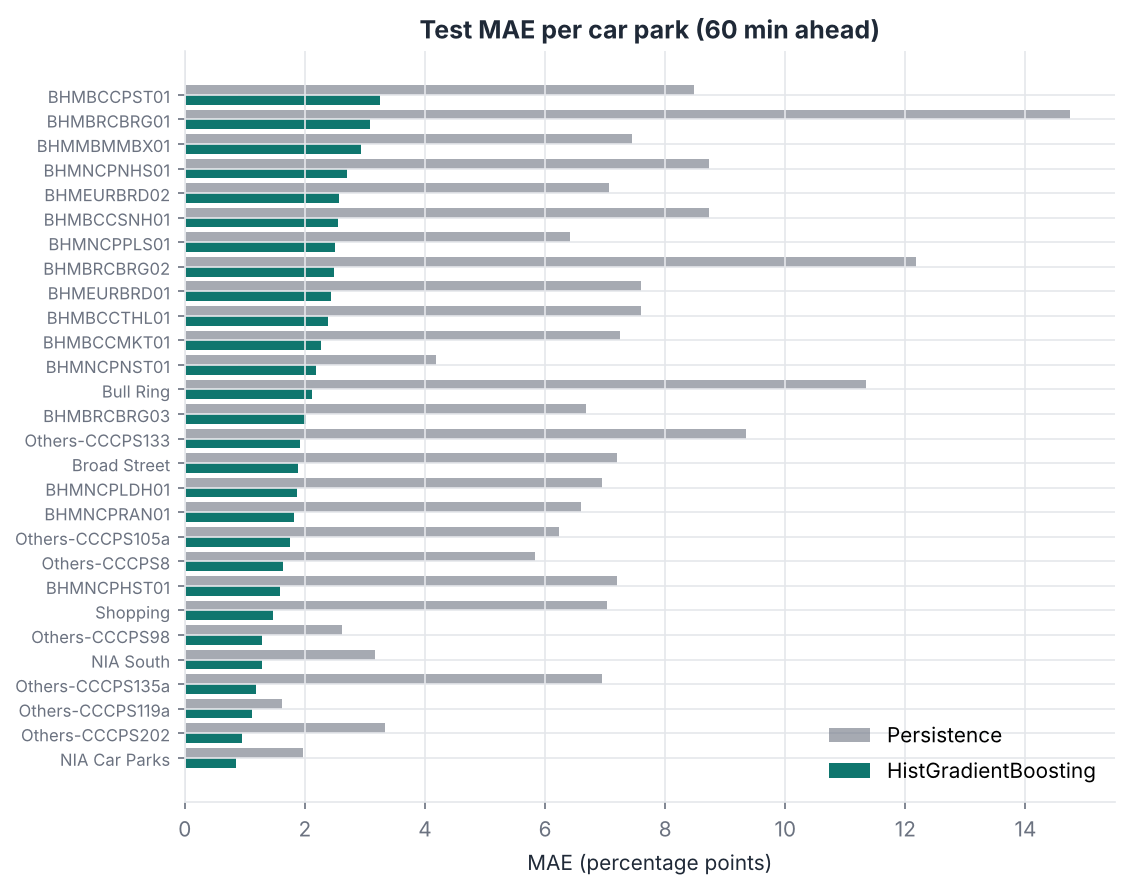

In [11]:
display(Image(ROOT / 'outputs/figures/eval_error_by_hour_h60.png'))
display(Image(ROOT / 'outputs/figures/eval_per_park_mae_h60.png'))

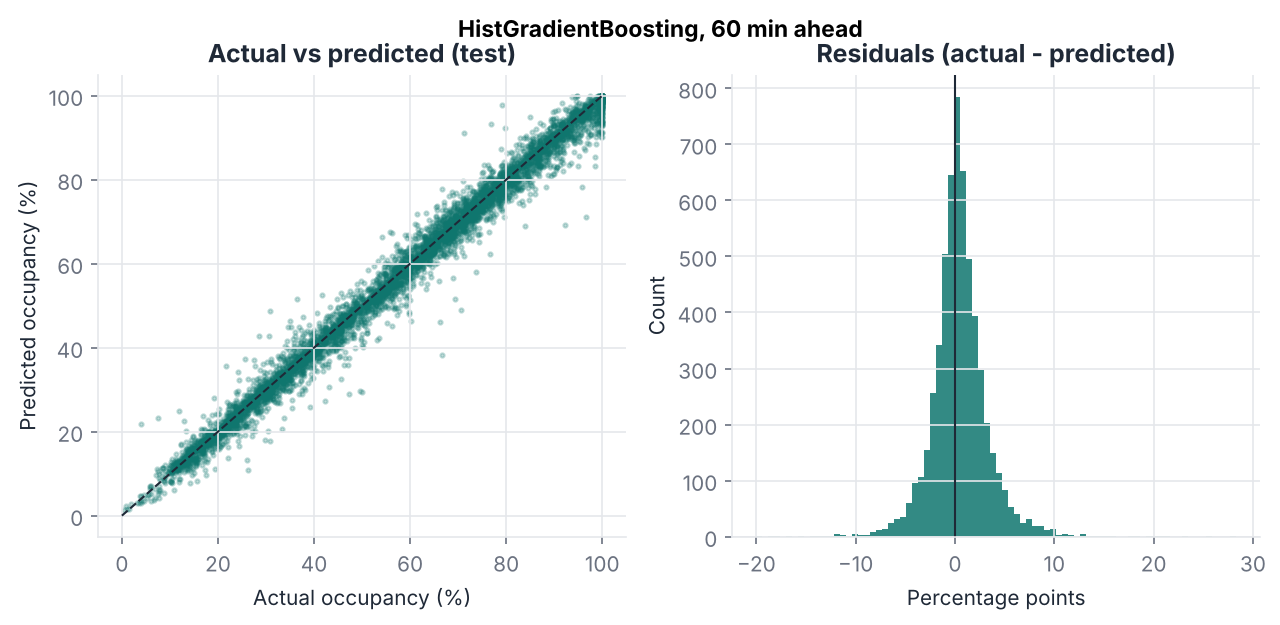

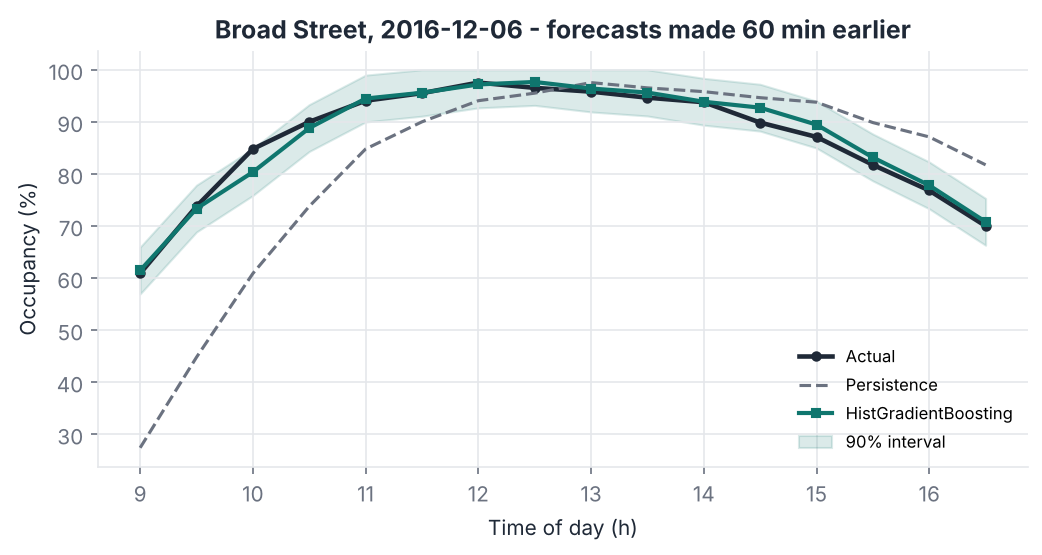

In [12]:
display(Image(ROOT / 'outputs/figures/eval_actual_vs_pred_h60.png'))
display(Image(ROOT / 'outputs/figures/eval_example_day_h60.png'))

In [13]:
pd.read_csv(C.METRICS_DIR / 'prediction_examples_h60.csv')

,SystemCodeNumber,slot_time,target_time,capacity,rate_now,target_rate,pred,target_status,clf::Thresholded HistGradientBoosting,error_pp,error_quantile
0,BHMBCCTHL01,2016-12-13 09:00:00,2016-12-13 10:00:00,387,0.6331,0.8165,0.8187,HIGH,HIGH,-0.22,10th pct
1,BHMEURBRD01,2016-12-14 12:00:00,2016-12-14 13:00:00,470,0.9319,0.9404,0.9543,FULL,FULL,-1.38,median
2,Others-CCCPS105a,2016-12-15 12:00:00,2016-12-15 13:00:00,2009,0.7048,0.7720,0.7272,HIGH,MODERATE,4.48,90th pct
3,BHMBCCSNH01,2016-12-11 10:30:00,2016-12-11 11:30:00,863,0.4299,0.6593,0.5583,MODERATE,MODERATE,10.10,99th pct


## Uncertainty and generalisation

In [14]:
{h: {'halfwidth_90_pp': ev[h]['interval_halfwidth_90_pp'], 'test_coverage': ev[h]['interval_test_coverage_90']} for h in ('30','60')}

{'30': {'halfwidth_90_pp': 2.87, 'test_coverage': 0.9016798418972332},
 '60': {'halfwidth_90_pp': 4.4990000000000006,
  'test_coverage': 0.9005053145147238}}

In [15]:
ev['unseen_park_experiment']

{'horizon_minutes': 60,
 'model': 'HistGradientBoosting',
 'n_test_rows': 5739,
 'unseen_park_MAE_pp': 2.7331545258557495,
 'seen_park_MAE_pp': 2.0209376296665136,
 'persistence_MAE_pp': 7.072741746899404}

## Interpretation

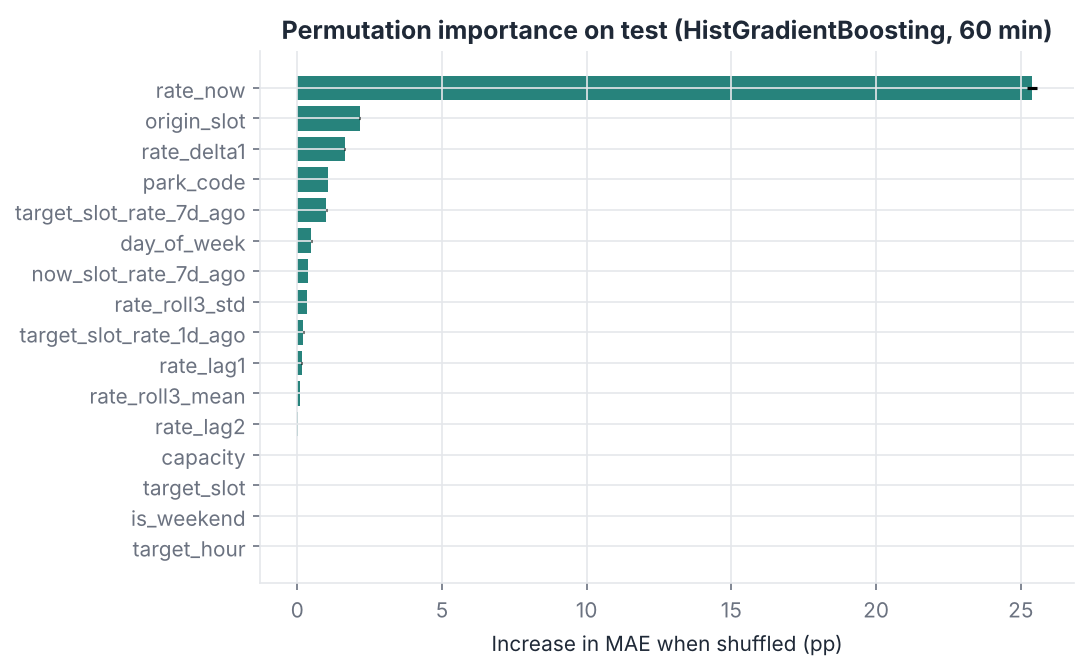

,feature,importance_MAE_increase_pp,std_pp
0,rate_now,25.3865,0.1732
1,origin_slot,2.1614,0.0180
2,rate_delta1,1.6347,0.0122
3,park_code,1.0678,0.0112
4,target_slot_rate_7d_ago,1.0112,0.0170
5,day_of_week,0.4886,0.0157
6,now_slot_rate_7d_ago,0.3687,0.0120
7,rate_roll3_std,0.3329,0.0085


In [16]:
display(Image(ROOT / 'outputs/figures/eval_permutation_importance_h60.png'))
pd.DataFrame(ev['60']['permutation_importance']).head(8)

## Conclusions from the experiments
* **ML beats every baseline at both horizons.** 60 min ahead, HistGradientBoosting has test MAE 2.02 pp (≈ 25 spaces) vs 7.07 pp
  for persistence, 7.24 pp for the historical profile and 2.79 pp for the strong *persistence + weekly shape* rule.
* **The strong rule matters.** Ridge regression (2.83 pp) does *not* beat it on test MAE, and Random Forest only beats it
  modestly. A project that compared ML only with persistence would overstate the value of ML.
* **Thresholding the regressor gives the best status classifier** (60 min: macro-F1 0.915, FULL recall 0.88, FULL precision 0.93),
  better than training a classifier directly; the regression output contains more information than the four labels.
* **Uncertainty is calibrated:** the ±4.5 pp range (from walk-forward residuals only) covered 90.1% of test outcomes.
* **Hardest cases:** the morning fill-up (10:00–11:30) and weekends, and a few car parks with irregular behaviour.
* **Generalisation:** for car parks never seen in training (ID hidden) MAE rises from 2.02 to 2.73 pp – still far better than
  persistence, so the learned patterns are not just memorised car-park identities.
* **Importance:** `rate_now` dominates; time of day (`origin_slot`), recent trend (`rate_delta1`), car-park ID and last week's value
  add the rest. `target_slot`/`target_hour` show ~0 importance only because they carry the same information as `origin_slot`
  (correlated features share importance) – not because time does not matter.
